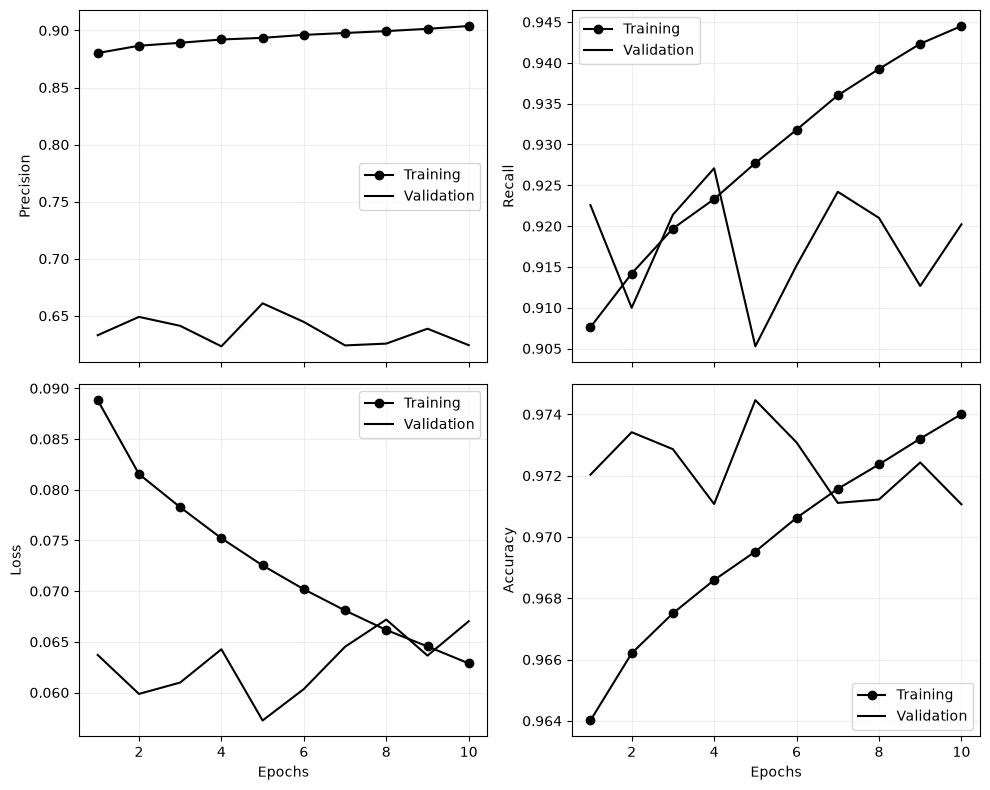

In [2]:
import numpy as np
import matplotlib.pyplot as plt

h = np.load("../outputs/results/cnn_history.npz")
epochs = range(1, len(h["loss"]) + 1)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True)

axes[0,0].plot(epochs, h["precision"], 'ko-', label="Training")
axes[0,0].plot(epochs, h["val_precision"], 'k', label="Validation")
axes[0,0].set_ylabel('Precision')
axes[0,0].grid(alpha=0.2)
axes[0,0].legend()

axes[0,1].plot(epochs, h["recall"], 'ko-', label="Training")
axes[0,1].plot(epochs, h["val_recall"], 'k', label="Validation")
axes[0,1].set_ylabel('Recall')
axes[0,1].grid(alpha=0.2)
axes[0,1].legend()

axes[1,0].plot(epochs, h["loss"], 'ko-', label="Training")
axes[1,0].plot(epochs, h["val_loss"], 'k', label="Validation")
axes[1,0].set_xlabel('Epochs')
axes[1,0].set_ylabel('Loss')
axes[1,0].grid(alpha=0.2)
axes[1,0].legend()

axes[1,1].plot(epochs, h["accuracy"], 'ko-', label="Training")
axes[1,1].plot(epochs, h["val_accuracy"], 'k', label="Validation")
axes[1,1].set_xlabel('Epochs')
axes[1,1].set_ylabel('Accuracy')
axes[1,1].grid(alpha=0.2)
axes[1,1].legend()

fig.tight_layout()
plt.show()

In [3]:
import numpy as np
import joblib
import matplotlib.pyplot as plt
import sys

def scores(label, m, score_map, thr):
    # pixel scores on the pixels selected by m, a pixel is "cut" if its score >= thr
    y_true = label[m]
    pred = score_map[m] >= thr
    tp = (y_true & pred).sum()
    fp = (~y_true & pred).sum()
    fn = (y_true & ~pred).sum()
    return tp / max(tp + fp, 1), tp / max(tp + fn, 1), tp / max(tp + fp + fn, 1)
    
data = np.load("../outputs/results/dataset.npz")
rf_data = joblib.load("../outputs/results/random_forest.joblib")

X = data["X"]
mask = data["mask"]
label = data["label"]
sets = data["sets"]

rf = rf_data["model"]
feats = rf_data["features"]

print("Model features:", feats)

H, W = mask.shape

proba_rf = np.full((H, W), np.nan, dtype="float32")
proba_rf[mask] = rf.predict_proba(X[mask.ravel()])[:, 1]

val = mask & (sets == 2)
test = mask & (sets == 3)
train = mask & (sets == 1)

thresholds = np.arange(0.05, 1.0, 0.05)

ious = [scores(label, val, proba_rf, t)[2] for t in thresholds]
best_threshold_rf = thresholds[np.argmax(ious)]

precision_rf, recall_rf, iou_rf = scores(label, test, proba_rf, best_threshold_rf)

print("Random Forest | threshold:", round(best_threshold_rf, 2),
      "| precision:", round(precision_rf, 3),
      "| recall:", round(recall_rf, 3),
      "| IoU:", round(iou_rf, 3))


Model features: ['NDVI_pre', 'NDVI_post', 'dNDVI', 'B02_post', 'dB02', 'B03_post', 'dB03', 'B04_post', 'dB04', 'B08_post', 'dB08', 'B11_post', 'dB11']
Random Forest | threshold: 0.85 | precision: 0.764 | recall: 0.771 | IoU: 0.623


In [7]:
import tensorflow as tf

cnn = tf.keras.models.load_model("../outputs/results/cnn.keras")

X_grid = X.reshape(H, W, len(feats))

mean = np.load("../outputs/results/cnn.npz")["mean"]
std = np.load("../outputs/results/cnn.npz")["std"]

X_grid = np.nan_to_num((X_grid - mean) / std).astype("float32")

patch_size = 7
pad = patch_size // 2
X_padded = np.pad(X_grid, ((pad, pad), (pad, pad), (0, 0)), mode="reflect")

train_mask = mask & (sets == 1)
val_mask = mask & (sets == 2)
test_mask = mask & (sets == 3)

test_idx = np.flatnonzero(test_mask)
val_idx = np.flatnonzero(val_mask)

proba_cnn = np.full((H, W), np.nan, dtype="float32")

for i in range(0, len(test_idx), 256):
    idx = test_idx[i:i+256]
    patches = np.array([X_padded[r:r+patch_size, c:c+patch_size, :]
                        for r, c in zip(idx // W, idx % W)])
    proba_cnn.ravel()[idx] = cnn.predict(patches, verbose=0).ravel()

test_idx = np.flatnonzero(test)

# PREDICTIONS
proba_cnn = np.full((H, W), np.nan, dtype="float32")

for indices in [val_idx, test_idx]:
    for i in range(0, len(indices), 256):
        idx = indices[i:i+256]
        patches = np.array([X_padded[r:r+patch_size, c:c+patch_size, :]
                            for r, c in zip(idx // W, idx % W)])
        proba_cnn.ravel()[idx] = cnn.predict(patches, verbose=0).ravel()

# THRESHOLD SELECTION ON VALIDATION
thresholds = np.arange(0.05, 1.0, 0.05)
ious = [scores(label, val_mask, proba_cnn, t)[2] for t in thresholds]
best_threshold_cnn = thresholds[np.argmax(ious)]

# EVALUATION ON TEST
precision_cnn, recall_cnn, iou_cnn = scores(label, test_mask, proba_cnn, best_threshold_cnn)

print("CNN | threshold:", round(best_threshold_cnn, 2),
      "| precision:", round(precision_cnn, 3),
      "| recall:", round(recall_cnn, 3),
      "| IoU:", round(iou_cnn, 3))
      
precision_cnn, recall_cnn, iou_cnn = scores(label, test, proba_cnn, best_threshold_cnn)

CNN | threshold: 0.7 | precision: 0.783 | recall: 0.839 | IoU: 0.681


In [5]:
import tensorflow as tf
import numpy as np

unet = tf.keras.models.load_model("../outputs/results/unet.keras")

data = np.load("../outputs/results/unet.npz")

mean = data["mean"]
std = data["std"]
best_threshold = float(data["threshold"])
patch_size = int(data["patch_size"])

print("threshold:", best_threshold)
print("patch size:", patch_size)

X_grid = X.reshape(H, W, len(feats))

X_grid = np.nan_to_num((X_grid - mean) / std).astype("float32")

pad = patch_size // 2

X_padded = np.pad(X_grid, ((pad, pad), (pad, pad), (0, 0)), mode="reflect")

train_mask = mask & (sets == 1)
val_mask = mask & (sets == 2)
test_mask = mask & (sets == 3)

proba_unet = np.load("../outputs/results/proba_unet.npy")

precision_unet, recall_unet, iou_unet = scores(label, test_mask, proba_unet, best_threshold)

print("UNET | threshold:", round(best_threshold, 2),
    "| precision:", round(precision_unet, 3),
    "| recall:", round(recall_unet, 3),
    "| IoU:", round(iou_unet, 3)
)

threshold: 0.5
patch size: 16
UNET | threshold: 0.5 | precision: 0.827 | recall: 0.795 | IoU: 0.681


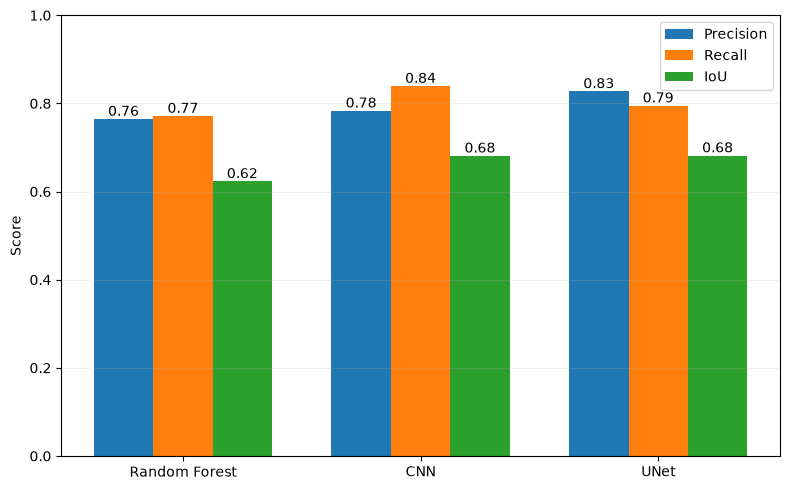

In [9]:
models = ["Random Forest", "CNN", "UNet"]
precision = [precision_rf, precision_cnn, precision_unet]
recall = [recall_rf, recall_cnn, recall_unet]
iou = [iou_rf, iou_cnn, iou_unet]

x = np.arange(len(models))
width = 0.25

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(x - width, precision, width, label="Precision")
ax.bar(x, recall, width, label="Recall")
ax.bar(x + width, iou, width, label="IoU")

ax.set_ylabel("Score")
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis="y", alpha=0.2)

for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f")
    
plt.tight_layout()
plt.show()

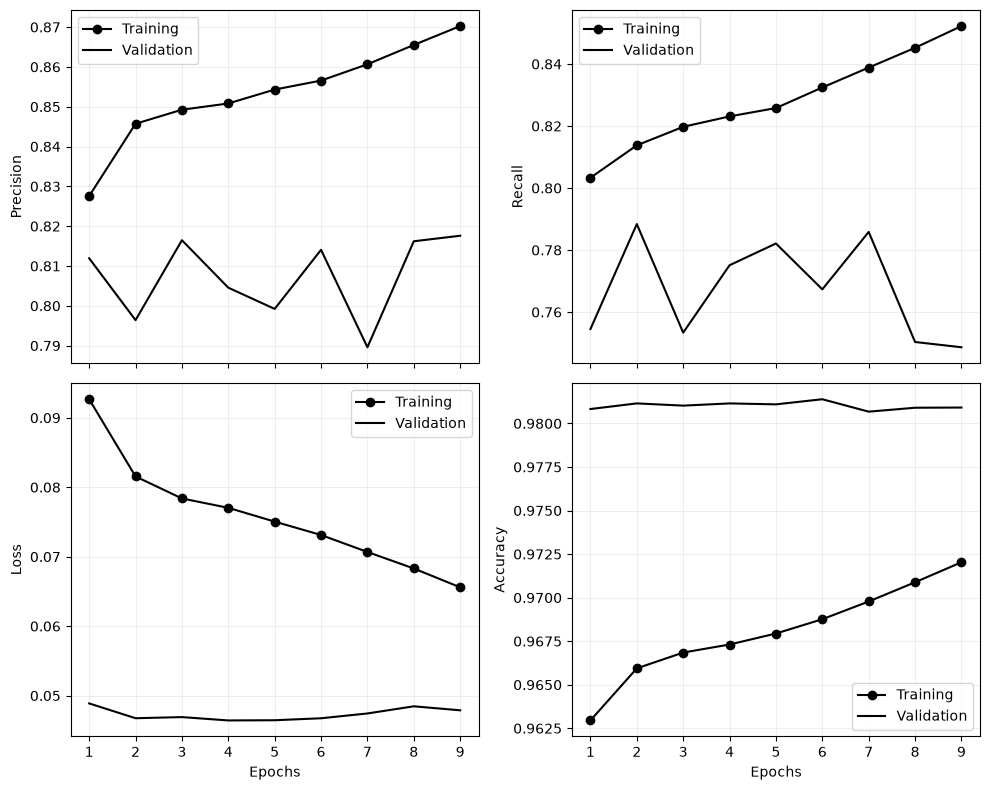

In [1]:
import numpy as np
import matplotlib.pyplot as plt

h = np.load("../outputs/results/unet_history.npz")
epochs = range(1, len(h["loss"]) + 1)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True)

axes[0,0].plot(epochs, h["precision"], 'ko-', label="Training")
axes[0,0].plot(epochs, h["val_precision"], 'k', label="Validation")
axes[0,0].set_ylabel('Precision')
axes[0,0].grid(alpha=0.2)
axes[0,0].legend()

axes[0,1].plot(epochs, h["recall"], 'ko-', label="Training")
axes[0,1].plot(epochs, h["val_recall"], 'k', label="Validation")
axes[0,1].set_ylabel('Recall')
axes[0,1].grid(alpha=0.2)
axes[0,1].legend()

axes[1,0].plot(epochs, h["loss"], 'ko-', label="Training")
axes[1,0].plot(epochs, h["val_loss"], 'k', label="Validation")
axes[1,0].set_xlabel('Epochs')
axes[1,0].set_ylabel('Loss')
axes[1,0].grid(alpha=0.2)
axes[1,0].legend()

axes[1,1].plot(epochs, h["accuracy"], 'ko-', label="Training")
axes[1,1].plot(epochs, h["val_accuracy"], 'k', label="Validation")
axes[1,1].set_xlabel('Epochs')
axes[1,1].set_ylabel('Accuracy')
axes[1,1].grid(alpha=0.2)
axes[1,1].legend()

fig.tight_layout()
plt.show()